# Dengue 2–4-week ward forecast — final analysis notebook

EDU AI Engineering Hackathon 2026 · Challenge: AI for Urban Dengue Outbreak

This notebook replaces `Untitled2 (1).ipynb` (kept unchanged in `backup/`). It runs top to bottom from a clean kernel and:

1. checks the organizer dataset,
2. builds features and the target with the shared module `features.py` (the same code `predict.py` uses),
3. reproduces the original chronological split, purge gap and XGBoost hyperparameters **without changes**,
4. re-evaluates the model correctly (the original alert metrics were computed on the HistGradientBoosting model by mistake),
5. compares against seasonal, persistence and mean baselines, including a rolling-origin evaluation by year,
6. defines and evaluates the four provisional risk tiers,
7. exports the model, `model_config.json` and evaluation files for the application.

**Forecast definition.** For ward *w* and issue week *t*: predicted dengue cases in weeks *t+2, t+3, t+4* combined. Inputs use only weeks ≤ *t* (week-*t* weather; cases up to week *t−1*).

**Data caveat.** The data ends 2025-12-29 and shows signs of being simulated (section 2). Results describe this dataset, not verified real-world surveillance.

## 0. Setup

In [1]:
import os, sys, json, time, hashlib, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, xgboost, joblib
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, precision_score,
                             recall_score, f1_score, confusion_matrix, classification_report)
from xgboost import XGBRegressor, DMatrix

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

PKG_DIR = Path.cwd()
sys.path.insert(0, str(PKG_DIR))
import features as F

DATA_PATH = PKG_DIR / "data" / "dengue_dataset.csv"
EVAL_DIR = PKG_DIR / "eval"; EVAL_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42
# Set to False to skip the ~5-minute randomized hyperparameter search (section 6b).
RUN_SLOW_EXPERIMENTS = True

def rmse(y, p): return float(np.sqrt(mean_squared_error(y, p)))

print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__, "| joblib", joblib.__version__)

python 3.13.18 | numpy 2.5.5 | pandas 3.1.1 | scikit-learn 1.6.1 | xgboost 3.4.1 | joblib 1.6.0


## 1. Load and check the organizer dataset

In [2]:
raw = pd.read_csv(DATA_PATH)
DATA_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print("shape:", raw.shape, "| sha256:", DATA_SHA256[:16], "...")
raw.head()

shape: (31320, 12) | sha256: a4088765084a0bcf ...


,date,city,ward_id,population_density_sqkm,water_logging_risk_index,sanitation_score,avg_temp_c,max_temp_c,min_temp_c,rainfall_mm,relative_humidity_pct,dengue_cases
0,2016-01-04,Chattogram,CCC_Ward_01,64024,0.87,0.46,18.32,26.54,14.13,0.00,59.24,0
1,2016-01-11,Chattogram,CCC_Ward_01,64024,0.87,0.46,21.24,26.95,16.71,2.02,61.63,0
2,2016-01-18,Chattogram,CCC_Ward_01,64024,0.87,0.46,20.94,25.05,14.84,0.00,60.50,0
3,2016-01-25,Chattogram,CCC_Ward_01,64024,0.87,0.46,21.75,27.20,17.58,1.52,69.02,0
4,2016-02-01,Chattogram,CCC_Ward_01,64024,0.87,0.46,22.39,28.02,16.98,0.94,60.50,0


In [3]:
df = F.prepare_records(raw)          # parses dates, sorts by ward_id/date, rejects duplicates
checks = {
    "rows": len(df),
    "columns": raw.shape[1],
    "missing values": int(raw.isna().sum().sum()),
    "duplicate rows": int(raw.duplicated().sum()),
    "duplicate ward-weeks": int(df.duplicated(["ward_id", "date"]).sum()),
    "first week": str(df.date.min().date()),
    "last week": str(df.date.max().date()),
    "weekly dates": df.date.nunique(),
    "all dates are Mondays": bool((df.date.dt.dayofweek == 0).all()),
    "wards": df.ward_id.nunique(),
    "cities": df.city.nunique(),
    "every ward has continuous 7-day steps": bool(df.groupby("ward_id").date.apply(lambda s: (s.diff().dropna() == pd.Timedelta(days=7)).all()).all()),
    "min<=avg<=max temperature everywhere": bool(((df.min_temp_c <= df.avg_temp_c) & (df.avg_temp_c <= df.max_temp_c)).all()),
    "negative rainfall/cases": int(((df.rainfall_mm < 0) | (df.dengue_cases < 0)).sum()),
    "humidity outside 0-100": int(((df.relative_humidity_pct < 0) | (df.relative_humidity_pct > 100)).sum()),
    "static ward attributes constant over time": bool((df.groupby("ward_id")[["population_density_sqkm","water_logging_risk_index","sanitation_score"]].nunique() == 1).all().all()),
}
pd.Series(checks, name="value").to_frame()

/tmp/ipykernel_247/1885716858.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  "all dates are Mondays": bool((df.date.dt.dayofweek == 0).all()),


,value
rows,31320
columns,12
missing values,0
duplicate rows,0
duplicate ward-weeks,0
first week,2016-01-04
last week,2025-12-29
weekly dates,522
all dates are Mondays,True
wards,60


In [4]:
print(df.groupby("city").ward_id.nunique().rename("wards").to_frame().T)
print("\nweekly dengue cases per ward:")
print(df.dengue_cases.describe().round(2).to_frame().T)
print("share of zero-case ward-weeks:", round((df.dengue_cases == 0).mean(), 3))

city   Chattogram  Dhaka North  Dhaka South  Gazipur  Narayanganj
wards          10           20           20        5            5

weekly dengue cases per ward:
                count  mean   std  min  25%  50%  75%   max
dengue_cases  31320.0  2.64  4.61  0.0  0.0  0.0  4.0  41.0
share of zero-case ward-weeks: 0.58


## 2. Exploratory analysis

The plots below kept from the original notebook show the seasonal cycle, case distribution and the lag structure that motivated the features. The last cell of this section documents provenance concerns.

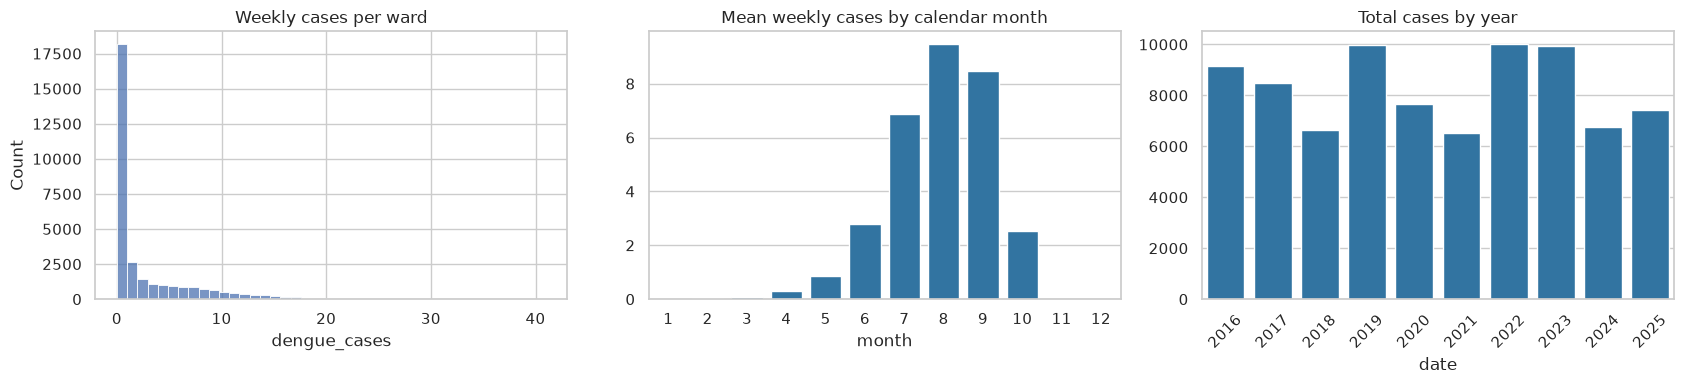

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(df.dengue_cases, bins=42, ax=axes[0]); axes[0].set_title("Weekly cases per ward")
monthly = df.groupby(df.date.dt.month).dengue_cases.mean()
sns.barplot(x=monthly.index, y=monthly.values, ax=axes[1], color="tab:blue"); axes[1].set_title("Mean weekly cases by calendar month"); axes[1].set_xlabel("month")
yearly = df.groupby(df.date.dt.year).dengue_cases.sum()
sns.barplot(x=yearly.index, y=yearly.values, ax=axes[2], color="tab:blue"); axes[2].set_title("Total cases by year"); axes[2].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

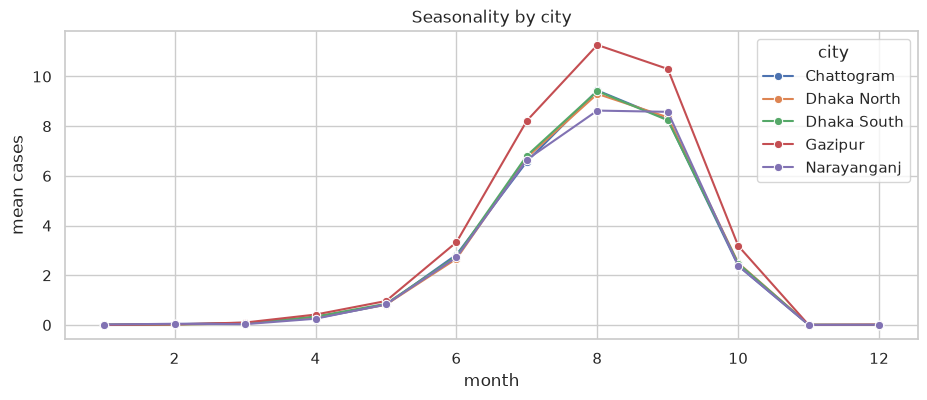

               sum  mean
city                    
Chattogram   13470  2.58
Dhaka North  27001  2.59
Dhaka South  27193  2.60
Gazipur       8295  3.18
Narayanganj   6613  2.53


In [6]:
monthly_city = df.groupby(["city", df.date.dt.month]).dengue_cases.mean().rename("mean cases").reset_index()
plt.figure(figsize=(11, 4))
sns.lineplot(data=monthly_city, x="date", y="mean cases", hue="city", marker="o")
plt.xlabel("month"); plt.title("Seasonality by city"); plt.show()
print(df.groupby("city").dengue_cases.agg(["sum", "mean"]).round(2))

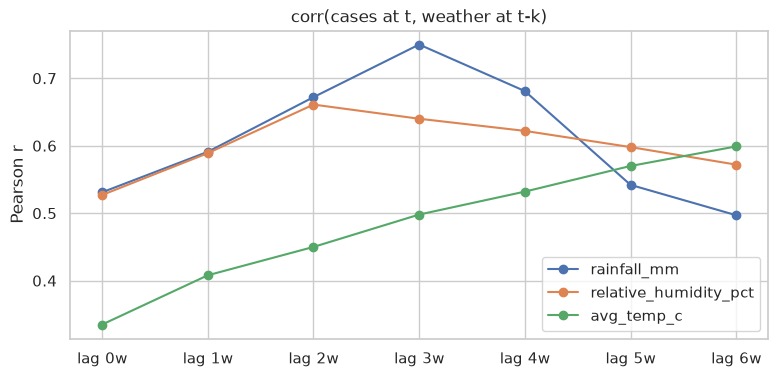

,rainfall_mm,relative_humidity_pct,avg_temp_c
lag 0w,0.531,0.527,0.335
lag 1w,0.591,0.589,0.408
lag 2w,0.672,0.661,0.450
lag 3w,0.750,0.640,0.498
lag 4w,0.681,0.622,0.532
lag 5w,0.542,0.598,0.570
lag 6w,0.497,0.572,0.599


In [7]:
# Correlation of weekly cases with weather k weeks earlier (same ward) — motivates multi-week lags.
lagcorr = {}
for col in ["rainfall_mm", "relative_humidity_pct", "avg_temp_c"]:
    lagcorr[col] = [df.dengue_cases.corr(df.groupby("ward_id")[col].shift(k)) for k in range(0, 7)]
lagcorr = pd.DataFrame(lagcorr, index=[f"lag {k}w" for k in range(0, 7)]).round(3)
ax = lagcorr.plot(marker="o", figsize=(9, 4), title="corr(cases at t, weather at t-k)"); ax.set_ylabel("Pearson r"); plt.show()
lagcorr

In [8]:
# Provenance check: how much does weather differ between wards in the same week?
w = ["avg_temp_c", "max_temp_c", "min_temp_c", "rainfall_mm", "relative_humidity_pct"]
spread = pd.DataFrame({
    "distinct values per week (max over weeks)": {c: df.groupby("date")[c].nunique().max() for c in w},
    "mean across-ward std per week": {c: round(df.groupby("date")[c].std().mean(), 3) for c in w},
})
rain_wide = df.pivot(index="date", columns="ward_id", values="rainfall_mm")
print("minimum pairwise correlation of weekly rainfall between any two wards:", round(rain_wide.corr().values.min(), 4))
spread

minimum pairwise correlation of weekly rainfall between any two wards: 0.9913


,distinct values per week (max over weeks),mean across-ward std per week
avg_temp_c,59,0.598
max_temp_c,1,0.000
min_temp_c,1,0.000
rainfall_mm,60,4.109
relative_humidity_pct,60,2.489


**Provenance finding.** `max_temp_c` and `min_temp_c` take a single value per week across all 60 wards, and weekly rainfall correlates ≥ 0.99 between every pair of wards — including wards in Chattogram and Dhaka, about 250 km apart. Cases correlate most strongly with rainfall exactly 3 weeks earlier, and fall to near zero from November to March. Together these suggest the data was generated by a simulation rather than collected from surveillance. Consequence: weather mostly tells the model **when** risk rises (almost identically in every ward); differences **between** wards come mainly from the three static vulnerability attributes.

## 3. Features and target (shared module `features.py`)

`build_features` only looks backward (calendar lags matched on ward and exact date), so the same code serves training and live inference. `build_target` is separate and is never called by `predict.py`.

The cell after this one rebuilds every feature with the **original notebook's** pandas `groupby().shift()` / `rolling()` code and checks that the values agree.

In [9]:
feat = F.build_features(raw)
target = F.build_target(raw)
print("feature rows:", len(feat), "| features:", len(F.FEATURE_COLUMNS),
      f"({len(F.NUMERIC_FEATURES)} numeric + {len(F.CATEGORICAL_FEATURES)} categorical)")
print("rows with complete features:", int(feat.features_complete.sum()), "| rows with defined target:", int(target.notna().sum()))
feat[["ward_id", "date", "rainfall_mm", "rainfall_lag_1w", "rainfall_lag_2w", "rainfall_lag_3w", "rainfall_lag_4w",
      "rain_roll4w_sum", "dengue_lag_1w", "history_weeks_available", "features_complete"]].head(6)

feature rows: 31320 | features: 32 (30 numeric + 2 categorical)
rows with complete features: 31080 | rows with defined target: 31080


,ward_id,date,rainfall_mm,rainfall_lag_1w,rainfall_lag_2w,rainfall_lag_3w,rainfall_lag_4w,rain_roll4w_sum,dengue_lag_1w,history_weeks_available,features_complete
0,CCC_Ward_01,2016-01-04,0.00,NaN,NaN,NaN,NaN,NaN,NaN,0,False
1,CCC_Ward_01,2016-01-11,2.02,0.00,NaN,NaN,NaN,NaN,0.0,1,False
2,CCC_Ward_01,2016-01-18,0.00,2.02,0.00,NaN,NaN,NaN,0.0,2,False
3,CCC_Ward_01,2016-01-25,1.52,0.00,2.02,0.00,NaN,NaN,0.0,3,False
4,CCC_Ward_01,2016-02-01,0.94,1.52,0.00,2.02,0.00,3.54,0.0,4,True
5,CCC_Ward_01,2016-02-08,4.17,0.94,1.52,0.00,2.02,4.48,0.0,4,True


In [10]:
# Independent reference: the original notebook's feature code (cells 41, 42, 43, 50 + the missing weather-lag cell).
ref = df.copy()
g = ref.groupby("ward_id")
for k in range(1, 5):
    ref[f"rainfall_lag_{k}w"] = g.rainfall_mm.shift(k)
    ref[f"temp_lag_{k}w"] = g.avg_temp_c.shift(k)
    ref[f"humidity_lag_{k}w"] = g.relative_humidity_pct.shift(k)
    ref[f"dengue_lag_{k}w"] = g.dengue_cases.shift(k)
for k in (2, 3, 4):
    ref[f"rain_roll{k}w_sum"] = g.rainfall_mm.transform(lambda x: x.shift(1).rolling(k).sum())
ref["dengue_roll4w_mean"] = g.dengue_cases.transform(lambda x: x.shift(1).rolling(4).mean())
ref["month_sin"] = np.sin(2 * np.pi * ref.date.dt.month / 12)
ref["month_cos"] = np.cos(2 * np.pi * ref.date.dt.month / 12)
ref_target = g.dengue_cases.shift(-2) + g.dengue_cases.shift(-3) + g.dengue_cases.shift(-4)

assert (feat.ward_id.values == ref.ward_id.values).all() and (feat.date.values == ref.date.values).all()
rows = []
for c in F.NUMERIC_FEATURES:
    a, b = feat[c].to_numpy(float), ref[c].to_numpy(float)
    assert np.array_equal(np.isnan(a), np.isnan(b)), c
    m = ~np.isnan(a)
    rows.append({"feature": c, "max |diff| (float64)": np.abs(a[m] - b[m]).max(),
                 "mismatches at float32 (XGBoost input precision)": int((a[m].astype(np.float32) != b[m].astype(np.float32)).sum())})
cmp = pd.DataFrame(rows)
assert cmp["mismatches at float32 (XGBoost input precision)"].sum() == 0
assert np.array_equal(np.isnan(target.values), np.isnan(ref_target.values)) and np.nanmax(np.abs(target.values - ref_target.values)) == 0
print("All 30 numeric features match the original definitions; target identical.")
cmp[cmp["max |diff| (float64)"] > 0]

All 30 numeric features match the original definitions; target identical.


,feature,max |diff| (float64),mismatches at float32 (XGBoost input precision)
12,rain_roll2w_sum,2.415845e-13,0
13,rain_roll3w_sum,2.273737e-13,0
14,rain_roll4w_sum,2.273737e-13,0


The only differences are in the three rolling rainfall sums: at most ~2e-13 mm, from pandas' running-sum arithmetic. `features.py` adds the 2–4 lag columns directly, so the value no longer depends on how much earlier history is loaded — this matters at inference time. The values are identical once cast to float32, which is the precision XGBoost uses internally, so model inputs are unchanged.

In [11]:
# Ward isolation: each ward's first week has no lags; and a lag never equals another ward's value by construction.
first_rows = feat.groupby("ward_id").head(1)
assert first_rows[[f"rainfall_lag_{k}w" for k in range(1, 5)]].isna().all().all()
fourth_rows = feat.groupby("ward_id").nth(3)
assert fourth_rows["rainfall_lag_4w"].isna().all() and fourth_rows["rainfall_lag_3w"].notna().all()
print("per-ward NaN counts for lags 1..4:", [int(feat.groupby("ward_id")[f"rainfall_lag_{k}w"].apply(lambda s: s.isna().sum()).max()) for k in range(1, 5)])

# Spot check across several wards and dates.
rng = np.random.default_rng(0)
for i in rng.choice(np.flatnonzero(feat.features_complete.values), size=8, replace=False):
    w, d = feat.ward_id.iat[i], feat.date.iat[i]
    for k in range(1, 5):
        expected = df.loc[(df.ward_id == w) & (df.date == d - pd.Timedelta(weeks=k)), "rainfall_mm"].item()
        assert feat[f"rainfall_lag_{k}w"].iat[i] == expected
print("spot checks passed for 8 random ward-weeks")

per-ward NaN counts for lags 1..4: [1, 2, 3, 4]
spot checks passed for 8 random ward-weeks


In [12]:
model_df = F.build_model_frame(raw)
print("model rows (features and target both defined):", len(model_df), "| expected 30840 (original cell 54)")
assert len(model_df) == 30840
target_col = F.TARGET_COLUMN
model_df[target_col].describe().round(2).to_frame().T

model rows (features and target both defined): 30840 | expected 30840 (original cell 54)


,count,mean,std,min,25%,50%,75%,max
future_dengue_cases_2_4w,30840.0,8.03,12.53,0.0,0.0,1.0,13.0,92.0


## 4. Chronological split with purge gap (unchanged from the original)

Cutoffs at 70 % and 85 % of the weekly dates. Training issue weeks end 4 weeks before the first cutoff and validation issue weeks end 4 weeks before the second, so no target window (t+2…t+4) crosses into the next period.

In [13]:
unique_dates = np.sort(model_df.date.unique())
train_cutoff = pd.Timestamp(unique_dates[int(len(unique_dates) * 0.70)])
val_cutoff = pd.Timestamp(unique_dates[int(len(unique_dates) * 0.85)])
PURGE = pd.Timedelta(weeks=4)

train_df = model_df[model_df.date <= train_cutoff - PURGE].copy()
val_df = model_df[(model_df.date > train_cutoff) & (model_df.date <= val_cutoff - PURGE)].copy()
test_df = model_df[model_df.date > val_cutoff].copy()

split_summary = pd.DataFrame({
    name: {"rows": len(d), "first issue week": d.date.min().date(), "last issue week": d.date.max().date(),
           "last target week": (d.date.max() + pd.Timedelta(weeks=4)).date()}
    for name, d in [("train", train_df), ("validation", val_df), ("test", test_df)]}).T
assert (len(train_df), len(val_df), len(test_df)) == (21360, 4380, 4620)
assert train_df.date.max() + pd.Timedelta(weeks=4) < val_df.date.min()
assert val_df.date.max() + pd.Timedelta(weeks=4) < test_df.date.min()
print("cutoffs:", train_cutoff.date(), val_cutoff.date())
split_summary

cutoffs: 2022-12-19 2024-06-10


,rows,first issue week,last issue week,last target week
train,21360,2016-02-01,2022-11-21,2022-12-19
validation,4380,2022-12-26,2024-05-13,2024-06-10
test,4620,2024-06-17,2025-12-01,2025-12-29


In [14]:
FEATURES, NUM, CAT = F.FEATURE_COLUMNS, F.NUMERIC_FEATURES, F.CATEGORICAL_FEATURES
X_train, y_train = train_df[FEATURES], train_df[target_col]
X_val, y_val = val_df[FEATURES], val_df[target_col]
X_test, y_test = test_df[FEATURES], test_df[target_col]

def make_preprocessor():
    # A fresh object for every pipeline (the original shared one object, which was refitted in place).
    return ColumnTransformer([("num", "passthrough", NUM),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])

XGB_PARAMS = dict(n_estimators=500, learning_rate=0.03, max_depth=5, min_child_weight=3, subsample=0.8,
                  colsample_bytree=0.8, reg_alpha=0.1, reg_lambda=2, objective="reg:squarederror",
                  eval_metric="rmse", random_state=RANDOM_STATE, n_jobs=-1)   # identical to the original

def xgb_pipeline(**overrides):
    return Pipeline([("preprocessor", make_preprocessor()), ("model", XGBRegressor(**{**XGB_PARAMS, **overrides}))])

## 5. Model selection on the validation period (same candidates as the original)

In [15]:
candidates = {
    "Dummy (mean)": DummyRegressor(strategy="mean"),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=20, min_samples_split=5, min_samples_leaf=2, random_state=42, n_jobs=-1),
    "Extra Trees": ExtraTreesRegressor(n_estimators=300, max_depth=20, min_samples_split=5, min_samples_leaf=2, random_state=42, n_jobs=-1),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_leaf_nodes=31, l2_regularization=1.0, random_state=42),
    "XGBoost": XGBRegressor(**XGB_PARAMS),
}
selection_rows, val_models = [], {}
for name, est in candidates.items():
    t0 = time.perf_counter()
    pipe = Pipeline([("preprocessor", make_preprocessor()), ("model", est)]).fit(X_train, y_train)
    p = np.maximum(pipe.predict(X_val), 0)
    val_models[name] = pipe
    selection_rows.append({"model": name, "val MAE": mean_absolute_error(y_val, p), "val RMSE": rmse(y_val, p),
                           "val R2": r2_score(y_val, p), "fit seconds": round(time.perf_counter() - t0, 1)})
selection = pd.DataFrame(selection_rows).sort_values("val MAE").reset_index(drop=True)
selection.round(4)

,model,val MAE,val RMSE,val R2,fit seconds
0,XGBoost,2.1371,4.3730,0.8936,1.8
1,Hist Gradient Boosting,2.2004,4.5150,0.8866,2.1
2,Extra Trees,2.2503,4.6331,0.8806,23.0
3,Random Forest,2.5142,5.3951,0.8381,75.9
4,Dummy (mean),10.2024,13.4561,-0.0072,0.0


In [16]:
xgb_val_model = val_models["XGBoost"]                     # the model family that is shipped
val_pred = np.maximum(xgb_val_model.predict(X_val), 0)
VAL_MAE, VAL_RMSE = mean_absolute_error(y_val, val_pred), rmse(y_val, val_pred)
print(f"XGBoost validation MAE {VAL_MAE:.4f} | RMSE {VAL_RMSE:.4f} | reference from audit: MAE 2.1371")

XGBoost validation MAE 2.1371 | RMSE 4.3730 | reference from audit: MAE 2.1371


### 5b. Alternatives that were tried and rejected (kept as evidence)

Each is evaluated on the same validation period. None beats the plain XGBoost configuration on MAE.

In [17]:
alt_rows = [{"variant": "XGBoost (shipped config)", "val MAE": VAL_MAE, "val RMSE": VAL_RMSE}]

# (a) log1p target
log_model = TransformedTargetRegressor(regressor=xgb_pipeline(), func=np.log1p, inverse_func=np.expm1).fit(X_train, y_train)
p = np.maximum(log_model.predict(X_val), 0)
alt_rows.append({"variant": "XGBoost, log1p target", "val MAE": mean_absolute_error(y_val, p), "val RMSE": rmse(y_val, p)})

# (b) sample weights favouring high-case weeks (original cell 125)
w = np.where(y_train > 30, 2.0, np.where(y_train > 13, 1.5, 1.0))
weighted = xgb_pipeline().fit(X_train, y_train, model__sample_weight=w)
p_weighted = np.maximum(weighted.predict(X_val), 0)
alt_rows.append({"variant": "XGBoost, sample-weighted", "val MAE": mean_absolute_error(y_val, p_weighted), "val RMSE": rmse(y_val, p_weighted)})

# (c) adding week-t case count (original cells 100-106 used an un-purged split; here the same purged split is used)
NUM_PLUS = NUM + ["dengue_cases"]
cur = df[["ward_id", "date", "dengue_cases"]]
tr_c = train_df.merge(cur, on=["ward_id", "date"]); va_c = val_df.merge(cur, on=["ward_id", "date"])
plus = Pipeline([("preprocessor", ColumnTransformer([("num", "passthrough", NUM_PLUS), ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])),
                 ("model", XGBRegressor(**XGB_PARAMS))]).fit(tr_c[NUM_PLUS + CAT], tr_c[target_col])
p = np.maximum(plus.predict(va_c[NUM_PLUS + CAT]), 0)
alt_rows.append({"variant": "XGBoost + week-t cases", "val MAE": mean_absolute_error(va_c[target_col], p), "val RMSE": rmse(va_c[target_col], p)})
pd.DataFrame(alt_rows).round(4)

,variant,val MAE,val RMSE
0,XGBoost (shipped config),2.1371,4.3730
1,"XGBoost, log1p target",2.3411,4.9224
2,"XGBoost, sample-weighted",2.2168,4.5392
3,XGBoost + week-t cases,2.1762,4.4733


In [18]:
# (d) randomized hyperparameter search with chronological folds (original cells 88-93). Slow: ~5 min on 2 CPUs.
if RUN_SLOW_EXPERIMENTS:
    tr_sorted = train_df.sort_values(["date", "ward_id"]).reset_index(drop=True)
    d_unique = np.sort(tr_sorted.date.unique())
    folds = []
    for tr_i, va_i in TimeSeriesSplit(n_splits=4, gap=4).split(d_unique):
        folds.append((np.flatnonzero(tr_sorted.date.isin(d_unique[tr_i])), np.flatnonzero(tr_sorted.date.isin(d_unique[va_i]))))
    grid = {"model__n_estimators": [300, 500, 700, 900], "model__max_depth": [3, 4, 5, 6],
            "model__learning_rate": [0.01, 0.02, 0.03, 0.05], "model__min_child_weight": [1, 3, 5, 7],
            "model__subsample": [0.7, 0.8, 0.9], "model__colsample_bytree": [0.7, 0.8, 0.9],
            "model__reg_alpha": [0, 0.1, 0.5, 1], "model__reg_lambda": [1, 2, 5, 10]}
    search = RandomizedSearchCV(xgb_pipeline(n_jobs=1, eval_metric="mae"), grid, n_iter=25, scoring="neg_mean_absolute_error",
                                cv=folds, random_state=42, n_jobs=-1).fit(tr_sorted[FEATURES], tr_sorted[target_col])
    p = np.maximum(search.best_estimator_.predict(X_val), 0)
    print("best chronological-CV MAE:", round(-search.best_score_, 4))
    print("best params:", search.best_params_)
    print(f"tuned model on validation: MAE {mean_absolute_error(y_val, p):.4f} vs shipped config {VAL_MAE:.4f}")
else:
    print("skipped (RUN_SLOW_EXPERIMENTS=False). Original run: tuned validation MAE 2.1827 vs 2.1371 untuned.")

best chronological-CV MAE: 3.0661
best params: {'model__subsample': 0.7, 'model__reg_lambda': 10, 'model__reg_alpha': 0.5, 'model__n_estimators': 700, 'model__min_child_weight': 1, 'model__max_depth': 6, 'model__learning_rate': 0.01, 'model__colsample_bytree': 0.7}
tuned model on validation: MAE 2.1827 vs shipped config 2.1371


## 6. Corrected binary alert evaluation (XGBoost)

**Fix for audit issue H1.** The original cells 128–131 used `best_model`, which was the HistGradientBoosting model, but labelled it XGBoost. Below, every number comes from the XGBoost validation model. "Actual outbreak" keeps the original definition: more than 30 cases in weeks t+2…t+4.

In [19]:
ACTUAL_HIGH = 30
y_val_hi = (y_val.values > ACTUAL_HIGH).astype(int)
thr_rows = []
for model_name, preds in [("XGBoost", val_pred), ("Hist Gradient Boosting (mislabelled in original)", np.maximum(val_models["Hist Gradient Boosting"].predict(X_val), 0))]:
    for t in [15, 20, 25, 30, 35, 40]:
        q = (preds > t).astype(int)
        thr_rows.append({"model": model_name, "alert if predicted >": t, "precision": precision_score(y_val_hi, q, zero_division=0),
                         "recall": recall_score(y_val_hi, q), "F1": f1_score(y_val_hi, q)})
thr = pd.DataFrame(thr_rows)
best_t = thr[thr.model == "XGBoost"].sort_values("F1", ascending=False).iloc[0]["alert if predicted >"]
print("validation F1-best alert threshold for XGBoost:", best_t)
thr.round(4)

validation F1-best alert threshold for XGBoost: 25


,model,alert if predicted >,precision,recall,F1
0,XGBoost,15,0.4489,1.0000,0.6197
1,XGBoost,20,0.5725,0.9709,0.7203
2,XGBoost,25,0.7216,0.8571,0.7836
3,XGBoost,30,0.8464,0.6561,0.7392
4,XGBoost,35,0.9121,0.4392,0.5929
5,XGBoost,40,0.9519,0.2619,0.4108
6,Hist Gradient Boosting (mislabelled in original),15,0.4420,0.9974,0.6125
7,Hist Gradient Boosting (mislabelled in original),20,0.5865,0.9683,0.7305
8,Hist Gradient Boosting (mislabelled in original),25,0.7650,0.8439,0.8025
9,Hist Gradient Boosting (mislabelled in original),30,0.8657,0.6481,0.7413


In [20]:
ALERT_THRESHOLD = 25          # original, validation-selected; confirmed above if best_t == 25
q = (val_pred > ALERT_THRESHOLD).astype(int)
print("VALIDATION, XGBoost, alert if predicted > 25 (rows = actual 0/1, cols = predicted 0/1)")
print(confusion_matrix(y_val_hi, q))
print(classification_report(y_val_hi, q, target_names=["not > 30", "> 30"], digits=4))

VALIDATION, XGBoost, alert if predicted > 25 (rows = actual 0/1, cols = predicted 0/1)
[[3877  125]
 [  54  324]]
              precision    recall  f1-score   support

    not > 30     0.9863    0.9688    0.9774      4002
        > 30     0.7216    0.8571    0.7836       378

    accuracy                         0.9591      4380
   macro avg     0.8539    0.9130    0.8805      4380
weighted avg     0.9634    0.9591    0.9607      4380



## 7. Final model: train on train + validation, test once

Same procedure as the original (cells 113–115). The test period is used only here and in the evaluation sections that follow; no choice is tuned on it.

In [21]:
final_train = pd.concat([train_df, val_df])
final_model = xgb_pipeline().fit(final_train[FEATURES], final_train[target_col])
test_raw = final_model.predict(X_test)
test_pred = np.maximum(test_raw, 0)
TEST = {"MAE (raw)": mean_absolute_error(y_test, test_raw), "RMSE (raw)": rmse(y_test, test_raw), "R2 (raw)": r2_score(y_test, test_raw),
        "MAE (clipped, as served)": mean_absolute_error(y_test, test_pred), "RMSE (clipped, as served)": rmse(y_test, test_pred),
        "R2 (clipped, as served)": r2_score(y_test, test_pred), "negative raw predictions": int((test_raw < 0).sum())}
REFERENCE = {"MAE (raw)": 2.7861, "RMSE (raw)": 4.9234, "R2 (raw)": 0.8132}
for k, v in REFERENCE.items():
    status = "matches" if abs(TEST[k] - v) < 5e-4 else "DIFFERS - investigate"
    print(f"{k}: {TEST[k]:.4f} (original notebook {v}) -> {status}")
print("first test row prediction:", round(float(test_pred[0]), 2), "(original notebook cell 137 printed 15.88)")
pd.Series(TEST).round(4).to_frame("test")

MAE (raw): 2.7861 (original notebook 2.7861) -> matches
RMSE (raw): 4.9234 (original notebook 4.9234) -> matches
R2 (raw): 0.8132 (original notebook 0.8132) -> matches
first test row prediction: 15.88 (original notebook cell 137 printed 15.88)


,test
MAE (raw),2.7861
RMSE (raw),4.9234
R2 (raw),0.8132
"MAE (clipped, as served)",2.7762
"RMSE (clipped, as served)",4.9225
"R2 (clipped, as served)",0.8132
negative raw predictions,377.0000


In [22]:
y_test_hi = (y_test.values > ACTUAL_HIGH).astype(int)
q = (test_pred > ALERT_THRESHOLD).astype(int)
cm = confusion_matrix(y_test_hi, q)
TEST_ALERT = {"precision": precision_score(y_test_hi, q), "recall": recall_score(y_test_hi, q), "F1": f1_score(y_test_hi, q),
              "true alerts": int(cm[1, 1]), "false alerts": int(cm[0, 1]), "missed outbreaks": int(cm[1, 0])}
print("TEST, alert if predicted > 25:"); print(cm)
pd.Series(TEST_ALERT).round(4).to_frame("test")

TEST, alert if predicted > 25:
[[3935  417]
 [  36  232]]


,test
precision,0.3575
recall,0.8657
F1,0.5060
true alerts,232.0000
false alerts,417.0000
missed outbreaks,36.0000


## 8. Baselines (same target, same test period, only information available at issue time)

* **Mean**: mean target over train + validation.
* **Persistence**: 3 × cases in week t−1, and 3 × the mean of weeks t−1…t−4 (a 3-week total needs ×3).
* **Seasonal climatology**: mean target for the same ward and ISO week of year, computed from train + validation rows only (their targets all end before the test period starts); falls back to the overall mean if a ward-week is unseen.

In [23]:
def woy(d): return d.dt.isocalendar().week.astype(int)

def baseline_predictions(hist, future):
    clim_ward = hist.assign(w=woy(hist.date)).groupby(["ward_id", "w"])[target_col].mean()
    clim_all = hist.assign(w=woy(hist.date)).groupby("w")[target_col].mean()
    keys = pd.MultiIndex.from_arrays([future.ward_id, woy(future.date)])
    return {
        "Mean (dummy)": np.full(len(future), hist[target_col].mean()),
        "Persistence: 3 x last week": 3 * future.dengue_lag_1w.values,
        "Persistence: 3 x 4-week mean": 3 * future.dengue_roll4w_mean.values,
        "Seasonal: week-of-year mean": woy(future.date).map(clim_all).fillna(hist[target_col].mean()).values,
        "Seasonal: ward x week-of-year mean": pd.Series(clim_ward.reindex(keys).values).fillna(hist[target_col].mean()).values,
    }

base = baseline_predictions(final_train, test_df)
bl_rows = [{"predictor": "XGBoost (final model)", "test MAE": TEST["MAE (clipped, as served)"], "test RMSE": TEST["RMSE (clipped, as served)"]}]
for name, p in base.items():
    bl_rows.append({"predictor": name, "test MAE": mean_absolute_error(y_test, p), "test RMSE": rmse(y_test, p)})
baselines = pd.DataFrame(bl_rows)
seasonal_mae = baselines.set_index("predictor").loc["Seasonal: ward x week-of-year mean", "test MAE"]
GAIN_VS_SEASONAL = 1 - TEST["MAE (clipped, as served)"] / seasonal_mae
GAIN_VS_SEASONAL_RAW = 1 - TEST["MAE (raw)"] / seasonal_mae
print(f"MAE reduction vs ward x week-of-year climatology: {GAIN_VS_SEASONAL:.1%} (clipped) / {GAIN_VS_SEASONAL_RAW:.1%} (raw predictions)")
baselines.round(4)

MAE reduction vs ward x week-of-year climatology: 13.9% (clipped) / 13.6% (raw predictions)


,predictor,test MAE,test RMSE
0,XGBoost (final model),2.7762,4.9225
1,Mean (dummy),9.5167,11.4080
2,Persistence: 3 x last week,7.2197,11.8451
3,Persistence: 3 x 4-week mean,7.5684,11.6315
4,Seasonal: week-of-year mean,3.6719,6.4790
5,Seasonal: ward x week-of-year mean,3.2232,5.8108


## 9. Rolling-origin evaluation by year

For each test year Y: train the same XGBoost configuration on issue weeks up to 5 weeks before 1 January of Y (so every training target ends before Y), then predict every issue week in Y. Baselines use the same training rows.

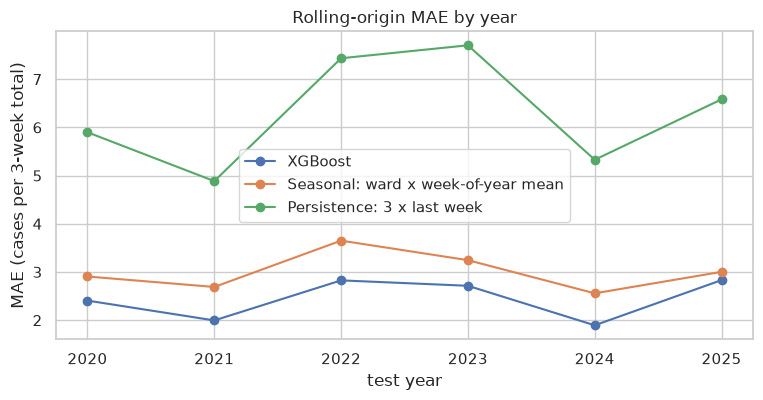

,test year,rows,XGBoost,Seasonal: ward x week-of-year mean,Persistence: 3 x last week,Mean (dummy),XGBoost gain vs seasonal
0,2020,3120,2.407,2.907,5.899,9.131,0.172
1,2021,3120,1.995,2.689,4.886,8.226,0.258
2,2022,3120,2.826,3.651,7.435,11.069,0.226
3,2023,3120,2.714,3.245,7.704,11.355,0.164
4,2024,3180,1.894,2.558,5.329,8.743,0.259
5,2025,2880,2.832,3.003,6.582,9.136,0.057


In [24]:
ro_rows, ro_preds = [], []
for Y in range(2020, 2026):
    hist = model_df[model_df.date <= pd.Timestamp(f"{Y}-01-01") - pd.Timedelta(weeks=5)]
    fut = model_df[model_df.date.dt.year == Y]
    m = xgb_pipeline().fit(hist[FEATURES], hist[target_col])
    p = np.maximum(m.predict(fut[FEATURES]), 0)
    b = baseline_predictions(hist, fut)
    row = {"test year": Y, "rows": len(fut), "XGBoost": mean_absolute_error(fut[target_col], p)}
    for name in ["Seasonal: ward x week-of-year mean", "Persistence: 3 x last week", "Mean (dummy)"]:
        row[name] = mean_absolute_error(fut[target_col], b[name])
    ro_rows.append(row)
    ro_preds.append(fut[["ward_id", "city", "date", target_col]].assign(predicted=p))
rolling = pd.DataFrame(ro_rows)
rolling["XGBoost gain vs seasonal"] = 1 - rolling["XGBoost"] / rolling["Seasonal: ward x week-of-year mean"]
ax = rolling.set_index("test year")[["XGBoost", "Seasonal: ward x week-of-year mean", "Persistence: 3 x last week"]].plot(marker="o", figsize=(9, 4))
ax.set_ylabel("MAE (cases per 3-week total)"); ax.set_title("Rolling-origin MAE by year"); plt.show()
rolling.round(3)

## 10. Where the model errs

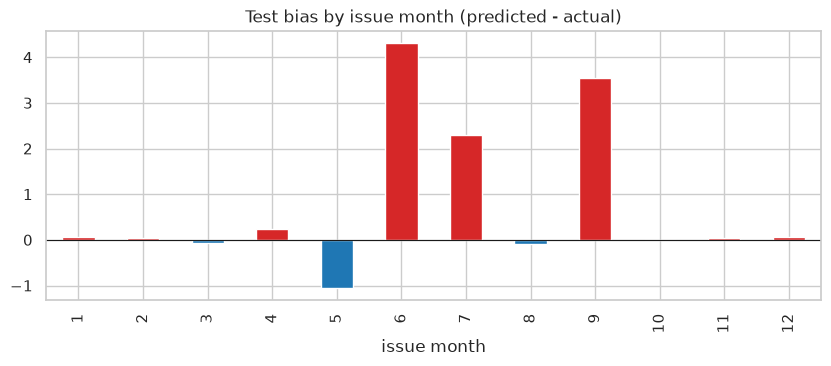

,rows,MAE,bias
city,,,
Chattogram,770,2.617,0.657
Dhaka North,1540,2.779,1.151
Dhaka South,1540,2.787,1.290
Gazipur,385,3.228,0.891
Narayanganj,385,2.589,0.973


,MAE,bias,mean_actual
issue month,,,
1,0.097,0.056,0.021
2,0.153,0.034,0.067
3,0.546,-0.066,0.530
4,1.070,0.240,1.804
5,4.185,-1.055,5.312
6,7.368,4.311,21.957
7,5.519,2.301,20.676
8,4.954,-0.087,25.348
9,4.562,3.543,9.062


In [25]:
test_out = test_df[["ward_id", "city", "date", target_col]].rename(columns={"date": "issue_week", target_col: "actual_cases_3wk"}).copy()
test_out["predicted_cases_3wk"] = test_pred
test_out["error"] = test_out.predicted_cases_3wk - test_out.actual_cases_3wk
by_city = test_out.groupby("city").agg(rows=("error", "size"), MAE=("error", lambda e: e.abs().mean()), bias=("error", "mean"))
by_month = test_out.groupby(test_out.issue_week.dt.month).agg(MAE=("error", lambda e: e.abs().mean()), bias=("error", "mean"),
                                                             mean_actual=("actual_cases_3wk", "mean"))
by_month.index.name = "issue month"
fig, ax = plt.subplots(figsize=(10, 3.5)); by_month["bias"].plot.bar(ax=ax, color=np.where(by_month.bias > 0, "tab:red", "tab:blue"))
ax.set_title("Test bias by issue month (predicted - actual)"); ax.axhline(0, color="k", lw=0.8); plt.show()
display(by_city.round(3)); by_month.round(3)

In [26]:
bands = pd.cut(test_out.actual_cases_3wk, [-1, 1, 13, 30, np.inf], labels=["0-1", "2-13", "14-30", ">30"])
test_out.groupby(bands, observed=False).agg(rows=("error", "size"), MAE=("error", lambda e: e.abs().mean()),
                                            mean_actual=("actual_cases_3wk", "mean"), mean_predicted=("predicted_cases_3wk", "mean")).round(3)

,rows,MAE,mean_actual,mean_predicted
actual_cases_3wk,,,,
0-1,2324,0.376,0.129,0.414
2-13,885,4.598,6.740,10.040
14-30,1143,5.221,20.872,22.878
>30,268,7.144,36.657,33.333


In [27]:
pi = permutation_importance(final_model, X_test, y_test, n_repeats=5, random_state=42, scoring="neg_mean_absolute_error", n_jobs=1)
imp = pd.DataFrame({"feature": FEATURES, "MAE increase when shuffled": pi.importances_mean}).sort_values("MAE increase when shuffled", ascending=False)
imp.head(12).round(3)

,feature,MAE increase when shuffled
6,rainfall_mm,1.756
7,relative_humidity_pct,0.707
1,water_logging_risk_index,0.542
28,month_sin,0.311
29,month_cos,0.298
17,temp_lag_3w,0.255
0,population_density_sqkm,0.184
15,temp_lag_1w,0.167
18,temp_lag_4w,0.151
4,max_temp_c,0.103


## 11. Risk tiers (provisional, model-defined)

Tiers are assigned from the **predicted 3-week case total** (after clipping at 0). Cut points sit halfway between integers, so every value — integer or not — has exactly one tier, and an integer count maps to the bands in the brief:

| Tier | Predicted 3-week total *p* | Integer equivalent |
| --- | --- | --- |
| Low | 0 ≤ p < 4.5 | 0–4 |
| Medium | 4.5 ≤ p < 14.5 | 5–14 |
| High | 14.5 ≤ p < 30.5 | 15–30 |
| Critical | p ≥ 30.5 | > 30 (the original outbreak definition) |

These are **not** clinical or official public-health thresholds. They are fixed bands on absolute case counts (no population data is available), chosen from the training distribution and the original "> 30" outbreak definition. They were not tuned on the test period.

Actual 3-week totals are put in tiers with the same bands so that predicted and actual tiers can be compared.

In [28]:
TIER_LABELS = ["Low", "Medium", "High", "Critical"]
TIER_EDGES = [4.5, 14.5, 30.5]          # lower bound inclusive for the next tier

def to_tier(values):
    return pd.Categorical(np.array(TIER_LABELS)[np.searchsorted(TIER_EDGES, np.asarray(values, float), side="right")],
                          categories=TIER_LABELS, ordered=True)

assert list(to_tier([0, 4.49, 4.5, 14.49, 14.5, 30.49, 30.5, 92])) == ["Low", "Low", "Medium", "Medium", "High", "High", "Critical", "Critical"]

# Justification on training data: how the actual target falls into the bands.
tier_share = pd.DataFrame({name: pd.Series(to_tier(d[target_col])).value_counts(normalize=True).reindex(TIER_LABELS)
                           for name, d in [("train", train_df), ("validation", val_df)]})
print("training target quantiles (50/75/90/95%):", train_df[target_col].quantile([.5, .75, .9, .95]).tolist())
tier_share.round(3)

training target quantiles (50/75/90/95%): [1.0, 14.0, 27.0, 36.0]


,train,validation
Low,0.635,0.736
Medium,0.126,0.077
High,0.162,0.100
Critical,0.077,0.086


In [29]:
from sklearn.metrics import cohen_kappa_score

def tier_report(y_true, y_pred, name):
    a, p = to_tier(y_true), to_tier(y_pred)
    cm = pd.crosstab(pd.Series(a, name="actual tier"), pd.Series(p, name="predicted tier"), dropna=False).reindex(index=TIER_LABELS, columns=TIER_LABELS, fill_value=0)
    ac, pc = np.asarray(a.codes), np.asarray(p.codes)
    crit_a, crit_p = ac == 3, pc == 3
    summary = {
        "rows": len(ac),
        "exact-tier accuracy": float((ac == pc).mean()),
        "within-one-tier accuracy": float((np.abs(ac - pc) <= 1).mean()),
        "macro F1": f1_score(ac, pc, average="macro"),
        "quadratic-weighted kappa": cohen_kappa_score(ac, pc, weights="quadratic"),
        "Critical recall": float(crit_p[crit_a].mean()) if crit_a.any() else np.nan,
        "Critical precision": float(crit_a[crit_p].mean()) if crit_p.any() else np.nan,
        "Critical false alerts (predicted Critical, actual not)": int((crit_p & ~crit_a).sum()),
        "missed Critical (actual Critical, predicted Low/Medium)": int((crit_a & (pc <= 1)).sum()),
        "missed Critical (actual Critical, predicted High)": int((crit_a & (pc == 2)).sum()),
    }
    return cm, pd.Series(summary, name=name)

cm_val, s_val = tier_report(y_val.values, val_pred, "validation")
cm_test, s_test = tier_report(y_test.values, test_pred, "test")
print("VALIDATION tier confusion (rows actual, cols predicted)"); display(cm_val)
print("TEST tier confusion"); display(cm_test)
TIER_SUMMARY = pd.concat([s_val, s_test], axis=1)
TIER_SUMMARY.round(4)

VALIDATION tier confusion (rows actual, cols predicted)


predicted tier,Low,Medium,High,Critical
actual tier,,,,
Low,3109,104,12,0
Medium,130,126,82,0
High,0,55,346,38
Critical,0,0,139,239


TEST tier confusion


predicted tier,Low,Medium,High,Critical
actual tier,,,,
Low,2535,127,20,0
Medium,65,245,293,5
High,10,70,815,167
Critical,0,0,108,160


,validation,test
rows,4380.0000,4620.0000
exact-tier accuracy,0.8721,0.8128
within-one-tier accuracy,0.9973,0.9924
macro F1,0.6940,0.6668
quadratic-weighted kappa,0.9269,0.8996
Critical recall,0.6323,0.5970
Critical precision,0.8628,0.4819
"Critical false alerts (predicted Critical, actual not)",38.0000,172.0000
"missed Critical (actual Critical, predicted Low/Medium)",0.0000,0.0000
"missed Critical (actual Critical, predicted High)",139.0000,108.0000


In [30]:
# Sensitivity of the Critical cut point, examined on VALIDATION only (not used to pick anything on test).
sens = []
for edge in [20.5, 25.0, 30.5]:
    pc = np.asarray(val_pred) >= edge; ac = y_val.values > 30
    sens.append({"Critical if predicted >=": edge, "Critical recall": pc[ac].mean(), "Critical precision": ac[pc].mean(), "predicted Critical rows": int(pc.sum())})
pd.DataFrame(sens).round(4)

,Critical if predicted >=,Critical recall,Critical precision,predicted Critical rows
0,20.5,0.9630,0.5909,616
1,25.0,0.8571,0.7216,449
2,30.5,0.6323,0.8628,277


**Tier logic decision.** The Critical cut stays at 30.5 so predicted and actual tiers mean the same thing. The model under-predicts the largest outbreaks, so Critical alone misses many actual > 30 weeks (see the recall above). To keep the early-warning behaviour validated in the original work, the output also carries `early_alert = predicted > 25` (the validation-selected threshold, section 6). The app should highlight a ward when **either** the tier is Critical **or** `early_alert` is true.

## 12. Per-forecast driver contributions

XGBoost can split each raw prediction into additive per-feature contributions (TreeSHAP, `pred_contribs=True`). They explain **how the model arrived at its number**, not what causes dengue. The check below confirms that contributions plus the bias term reproduce the model output.

In [31]:
DRIVER_GROUPS = {
    "Rainfall (this week)": ["rainfall_mm"],
    "Rainfall (previous 1-4 weeks)": ["rainfall_lag_1w", "rainfall_lag_2w", "rainfall_lag_3w", "rainfall_lag_4w", "rain_roll2w_sum", "rain_roll3w_sum", "rain_roll4w_sum"],
    "Humidity": ["relative_humidity_pct", "humidity_lag_1w", "humidity_lag_2w", "humidity_lag_3w", "humidity_lag_4w"],
    "Temperature": ["avg_temp_c", "max_temp_c", "min_temp_c", "temp_lag_1w", "temp_lag_2w", "temp_lag_3w", "temp_lag_4w"],
    "Recent dengue cases": ["dengue_lag_1w", "dengue_lag_2w", "dengue_lag_3w", "dengue_lag_4w", "dengue_roll4w_mean"],
    "Ward vulnerability": ["population_density_sqkm", "water_logging_risk_index", "sanitation_score"],
    "Season (month)": ["month_sin", "month_cos"],
    "Ward / city identity": ["city", "ward_id"],
}
assert sorted(sum(DRIVER_GROUPS.values(), [])) == sorted(FEATURES)

pre, booster = final_model.named_steps["preprocessor"], final_model.named_steps["model"].get_booster()
out_names = list(pre.get_feature_names_out())
def source_feature(n):
    base = n.split("__", 1)[1]
    for c in CAT:
        if base.startswith(c + "_"):
            return c
    return base
col_group = np.array([next(g for g, fs in DRIVER_GROUPS.items() if source_feature(n) in fs) for n in out_names])

contrib = booster.predict(DMatrix(pre.transform(X_test)), pred_contribs=True)
max_gap = np.abs(contrib.sum(axis=1) - test_raw).max()
print("max |sum(contributions) - model output| over the test set:", max_gap)
assert max_gap < 1e-3
grouped = pd.DataFrame({g: contrib[:, :-1][:, col_group == g].sum(axis=1) for g in DRIVER_GROUPS})
grouped.abs().mean().sort_values(ascending=False).round(3).to_frame("mean |contribution| on test")

max |sum(contributions) - model output| over the test set: 5.9127808e-05


,mean |contribution| on test
Rainfall (this week),4.352
Humidity,2.474
Rainfall (previous 1-4 weeks),2.200
Temperature,2.077
Ward vulnerability,1.846
Season (month),0.712
Recent dengue cases,0.535
Ward / city identity,0.038


## 13. Export model, configuration and evaluation files

In [32]:
MODEL_VERSION = "dengue-xgb-2to4w-1.1.0"
joblib.dump(final_model, PKG_DIR / "dengue_xgboost_model.joblib")

numeric_ranges = {c: {"min": float(final_train[c].min()), "max": float(final_train[c].max())} for c in NUM}
ward_city = df.drop_duplicates("ward_id").set_index("ward_id").city.to_dict()
complete_weeks = feat.loc[feat.features_complete, "date"]
config = {
    "model_version": MODEL_VERSION,
    "model_file": "dengue_xgboost_model.joblib",
    "model_type": "sklearn Pipeline(ColumnTransformer[passthrough numeric, OneHotEncoder(handle_unknown='ignore') categorical] -> XGBRegressor)",
    "feature_set_version": F.FEATURE_SET_VERSION,
    "target": F.TARGET_COLUMN,
    "target_definition": "Sum of dengue cases in weeks t+2, t+3 and t+4 for the same ward, where t is the issue week",
    "horizon_weeks": list(F.TARGET_HORIZON_WEEKS),
    "issue_time_assumption": "Forecast for week t is issued after week t's weather and week t-1's case counts are known; week t's own case count is not used",
    "numeric_features": NUM,
    "categorical_features": CAT,
    "feature_columns": FEATURES,
    "min_history_weeks": F.MIN_HISTORY_WEEKS,
    "hyperparameters": {k: v for k, v in XGB_PARAMS.items() if k != "n_jobs"},
    "prediction_constraint": "Raw model output is clipped at 0 before tiers are assigned",
    "risk_tiers": {
        "labels": TIER_LABELS,
        "edges": TIER_EDGES,
        "rule": "tier = Low if p < 4.5; Medium if 4.5 <= p < 14.5; High if 14.5 <= p < 30.5; Critical if p >= 30.5 (p = clipped predicted 3-week total)",
        "integer_ranges": {"Low": "0-4", "Medium": "5-14", "High": "15-30", "Critical": ">30"},
        "status": "Provisional model-defined categories on absolute case counts; not clinical or official public-health thresholds",
    },
    "early_alert": {"rule": "predicted_cases_3wk > 25", "threshold": ALERT_THRESHOLD,
                    "basis": "Best validation F1 for detecting actual 3-week totals > 30 (XGBoost validation model)"},
    "actual_high_risk_threshold": ACTUAL_HIGH,
    "driver_groups": DRIVER_GROUPS,
    "ward_city": ward_city,
    "valid_issue_weeks": {"first": str(complete_weeks.min().date()), "last": str(complete_weeks.max().date()), "weekday": "Monday",
                          "actuals_available_until_issue_week": str((df.date.max() - pd.Timedelta(weeks=4)).date())},
    "numeric_ranges_train": numeric_ranges,
    "training_data": {"file": "data/dengue_dataset.csv", "sha256": DATA_SHA256, "rows": int(len(raw)),
                      "first_week": str(df.date.min().date()), "last_week": str(df.date.max().date()),
                      "final_model_training_rows": int(len(final_train)),
                      "final_model_training_issue_weeks": [str(final_train.date.min().date()), str(final_train.date.max().date())]},
    "split": {"train_cutoff": str(train_cutoff.date()), "validation_cutoff": str(val_cutoff.date()), "purge_weeks": 4,
              "rows": {"train": len(train_df), "validation": len(val_df), "test": len(test_df)}},
    "metrics": {"validation_MAE": round(VAL_MAE, 4), "validation_RMSE": round(VAL_RMSE, 4),
                **{f"test_{k}": round(float(v), 4) for k, v in TEST.items()},
                "test_MAE_seasonal_ward_woy_baseline": round(float(seasonal_mae), 4),
                "test_MAE_reduction_vs_seasonal": round(float(GAIN_VS_SEASONAL), 4)},
    "library_versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                         "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__, "joblib": joblib.__version__},
}
(PKG_DIR / "model_config.json").write_text(json.dumps(config, indent=2, default=str))

# Evaluation files for the dashboard
test_out["predicted_tier"] = to_tier(test_out.predicted_cases_3wk).astype(str)
test_out["actual_tier"] = to_tier(test_out.actual_cases_3wk).astype(str)
test_out["early_alert"] = test_out.predicted_cases_3wk > ALERT_THRESHOLD
test_out.assign(issue_week=test_out.issue_week.dt.date).round(4).to_csv(EVAL_DIR / "test_predictions.csv", index=False)
val_out = val_df[["ward_id", "city", "date", target_col]].rename(columns={"date": "issue_week", target_col: "actual_cases_3wk"}).assign(predicted_cases_3wk=val_pred, model="XGBoost trained on train period only")
val_out.assign(issue_week=val_out.issue_week.dt.date).round(4).to_csv(EVAL_DIR / "validation_predictions.csv", index=False)
pd.concat(ro_preds).rename(columns={"date": "issue_week", target_col: "actual_cases_3wk", "predicted": "predicted_cases_3wk"}).assign(
    issue_week=lambda d: d.issue_week.dt.date).round(4).to_csv(EVAL_DIR / "rolling_origin_predictions.csv", index=False)
rolling.round(4).to_csv(EVAL_DIR / "rolling_origin_by_year.csv", index=False)
baselines.round(4).to_csv(EVAL_DIR / "baselines_test.csv", index=False)
selection.round(4).to_csv(EVAL_DIR / "model_selection_validation.csv", index=False)
thr.round(4).to_csv(EVAL_DIR / "alert_thresholds_validation.csv", index=False)
cm_val.to_csv(EVAL_DIR / "tier_confusion_validation.csv"); cm_test.to_csv(EVAL_DIR / "tier_confusion_test.csv")
test_out.groupby("ward_id").agg(city=("city", "first"), MAE=("error", lambda e: e.abs().mean()), bias=("error", "mean")).round(4).to_csv(EVAL_DIR / "test_error_by_ward.csv")
by_month.round(4).to_csv(EVAL_DIR / "test_error_by_month.csv"); by_city.round(4).to_csv(EVAL_DIR / "test_error_by_city.csv")
summary = {"model_version": MODEL_VERSION, "validation": {"MAE": VAL_MAE, "RMSE": VAL_RMSE}, "test": TEST, "test_alert_gt25": TEST_ALERT,
           "tiers": TIER_SUMMARY.to_dict(), "gain_vs_seasonal": GAIN_VS_SEASONAL}
(EVAL_DIR / "metrics_summary.json").write_text(json.dumps(summary, indent=2, default=float))
print("wrote:", sorted(p.name for p in PKG_DIR.glob("*.joblib")), "model_config.json and", sorted(p.name for p in EVAL_DIR.iterdir()))

wrote: ['dengue_xgboost_model.joblib'] model_config.json and ['alert_thresholds_validation.csv', 'baselines_test.csv', 'metrics_summary.json', 'model_selection_validation.csv', 'rolling_origin_by_year.csv', 'rolling_origin_predictions.csv', 'test_error_by_city.csv', 'test_error_by_month.csv', 'test_error_by_ward.csv', 'test_predictions.csv', 'tier_confusion_test.csv', 'tier_confusion_validation.csv', 'validation_predictions.csv']


## 14. Conclusions

In [33]:
print(f"Validation MAE {VAL_MAE:.4f}; test MAE {TEST['MAE (raw)']:.4f} raw / {TEST['MAE (clipped, as served)']:.4f} clipped; test RMSE {TEST['RMSE (raw)']:.4f}; R2 {TEST['R2 (raw)']:.4f}.")
print(f"Seasonal ward x week climatology test MAE {seasonal_mae:.4f}; XGBoost is {GAIN_VS_SEASONAL:.1%} lower.")
print(f"Rolling-origin: XGBoost beats seasonal climatology in {int((rolling['XGBoost gain vs seasonal'] > 0).sum())} of {len(rolling)} years "
      f"(gain {rolling['XGBoost gain vs seasonal'].min():.1%} to {rolling['XGBoost gain vs seasonal'].max():.1%}).")
print(f"Test alert (>25): precision {TEST_ALERT['precision']:.3f}, recall {TEST_ALERT['recall']:.3f}, {TEST_ALERT['false alerts']} false alerts.")
print(f"Test tiers: exact {s_test['exact-tier accuracy']:.3f}, within one {s_test['within-one-tier accuracy']:.3f}, macro F1 {s_test['macro F1']:.3f}, Critical recall {s_test['Critical recall']:.3f}.")

Validation MAE 2.1371; test MAE 2.7861 raw / 2.7762 clipped; test RMSE 4.9234; R2 0.8132.
Seasonal ward x week climatology test MAE 3.2232; XGBoost is 13.9% lower.
Rolling-origin: XGBoost beats seasonal climatology in 6 of 6 years (gain 5.7% to 25.9%).
Test alert (>25): precision 0.357, recall 0.866, 417 false alerts.
Test tiers: exact 0.813, within one 0.992, macro F1 0.667, Critical recall 0.597.


* The original XGBoost configuration, target, split and purge gap are kept unchanged; the results above reproduce the original notebook's numbers.
* The model adds real skill over a strong seasonal baseline in every year tested, but the margin varies by year.
* Weaknesses: it over-forecasts at the start of the season (June) and in September, which produces false alerts, and it under-forecasts the largest outbreaks, so Critical recall is limited — use `early_alert` alongside the tier.
* Ward differences come mostly from static vulnerability attributes because the weather is almost identical across wards in this dataset.
* The data ends 2025-12-29. The application must present outputs as a historical replay, not live November 2026 warnings. The data appears simulated, and counts are absolute (not per population).
* Tiers are provisional model-defined bands, not public-health standards. Predictions should be reviewed by public-health staff before any real decision.